In [3]:
import joblib

X_train_processed = joblib.load("../model_dir/artifacts_dir/X_train_processed.pkl")
X_test_processed = joblib.load("../model_dir/artifacts_dir/X_test_processed.pkl")
y_train = joblib.load("../model_dir/artifacts_dir/y_train.pkl")
y_test = joblib.load("../model_dir/artifacts_dir/y_test.pkl")

In [4]:
print(X_train_processed.shape)
print(X_test_processed.shape)
print(y_train.shape)
print(y_test.shape)

(1940, 830)
(486, 830)
(1940,)
(486,)


In [5]:
# step 2: train Logistic Regression.

from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

log_model.fit(X_train_processed, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:

In [6]:
# Step 3 — Predict on train and test data


ypred_train = log_model.predict(X_train_processed)

ypred_test = log_model.predict(X_test_processed)

print("Train predictions:", ypred_train.shape)
print("Test predictions:", ypred_test.shape)

Train predictions: (1940,)
Test predictions: (486,)


In [7]:
# Step 4 — Accuracy
from sklearn.metrics import accuracy_score

train_accuracy = accuracy_score(y_train, ypred_train)
test_accuracy = accuracy_score(y_test, ypred_test)

print("Train Accuracy:", train_accuracy)
print("Test Accuracy:", test_accuracy)

Train Accuracy: 0.9365979381443299
Test Accuracy: 0.8683127572016461


In [8]:
# Classification Report
from sklearn.metrics import classification_report

print(classification_report(y_test, ypred_test))

              precision    recall  f1-score   support

           0       0.95      0.91      0.93       444
           1       0.32      0.45      0.37        42

    accuracy                           0.87       486
   macro avg       0.63      0.68      0.65       486
weighted avg       0.89      0.87      0.88       486



Note:
The important metric for us is Class 1 (Expired) because it is the minority class and clinically important.

Precision = 0.32 → Of patients predicted as Expired, only 32% were actually Expired.
Recall = 0.45 → The model detected 45% of the actual Expired patients.
F1 = 0.37 → Overall performance for the Expired class is still weak.

So although accuracy is 86.8%, we should not say the model is good based on accuracy alone.

In [9]:
# Confusion Matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, ypred_test)

print(cm)

[[403  41]
 [ 23  19]]


In [ ]:
'''
Note:

[[403  41]
 [ 23  19]]

For binary classification, the order is:

                 Predicted
                 0       1
Actual  0       403      41
Actual  1        23      19

So:

403 = True Negative (TN) → Actually Alive, predicted Alive
41 = False Positive (FP) → Actually Alive, predicted Expired
23 = False Negative (FN) → Actually Expired, predicted Alive
19 = True Positive (TP) → Actually Expired, predicted Expired
Connect this to your recall

There were 42 actual Expired patients:

23 + 19 = 42

Model correctly found 19:

Recall = 19 / (19 + 23)
       = 19 / 42
       = 45.2%

That's why your Expired recall = 0.45.

Connect this to precision

Model predicted 60 patients as Expired:

41 + 19 = 60

Actually, from this matrix:

Precision = 19 / (41 + 19)
         = 19 / 60
         = 31.7%

That's why Expired precision = 0.32.

So the main issue is clear:

The model correctly detects only 19 out of 42 actual Expired cases. It misses 23 Expired cases.

This is why we should look at recall, F1 and ROC-AUC, not accuracy alone.

'''

In [10]:


#Step 5 — Get prediction probabilities
#This gives the model's probability of Class 1 = Expired.
yprob_test = log_model.predict_proba(X_test_processed)[:, 1]

print(yprob_test[:10])

''' 
These are probabilities of Class 1 (Expired).

For example:

0.0018 → 0.18% probability of Expired
0.1905 → 19.05%
0.0445 → 4.45%
0.3746 → 37.46%

These probabilities are useful for ROC-AUC because ROC-AUC evaluates,
 how well the model ranks Expired patients above Alive patients across different thresholds.
'''


[1.82343412e-03 1.90565061e-01 4.45094860e-02 3.15235058e-04
 6.02682812e-03 2.44711956e-02 1.07592361e-05 3.74581169e-01
 2.95583398e-02 1.70452754e-02]


' \nThese are probabilities of Class 1 (Expired).\n\nFor example:\n\n0.0018 → 0.18% probability of Expired\n0.1905 → 19.05%\n0.0445 → 4.45%\n0.3746 → 37.46%\n\nThese probabilities are useful for ROC-AUC because ROC-AUC evaluates,\n how well the model ranks Expired patients above Alive patients across different thresholds.\n'

In [11]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_test, yprob_test)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.7456563706563707


In [ ]:
'''
Results:

Current Logistic Regression results
Accuracy       = 86.83%
Expired Precision = 32%
Expired Recall    = 45%
Expired F1        = 37%
ROC-AUC        = 0.746

Important: Don't conclude the model is good from accuracy alone. The Expired recall of 45% is relatively low.

'''

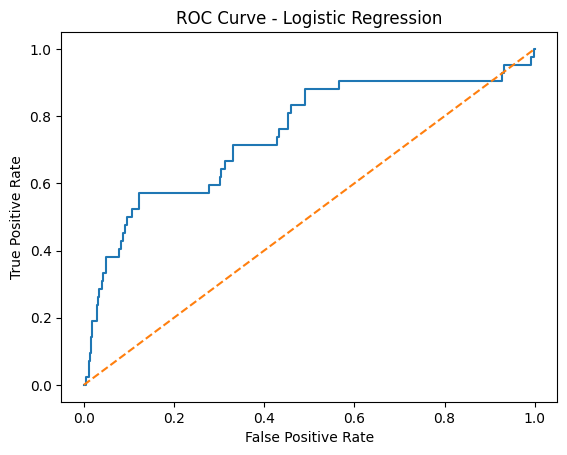

In [12]:
#Step 6 — ROC Curve



from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, yprob_test)

plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")

plt.show()

RANDOM FOREST   

In [13]:
# Train Random Forest
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [14]:
#Predictions
ypred_train_rf = rf_model.predict(X_train_processed)

ypred_test_rf = rf_model.predict(X_test_processed)


print("Train predictions:", ypred_train_rf.shape)
print("Test predictions:", ypred_test_rf.shape)

Train predictions: (1940,)
Test predictions: (486,)


In [15]:
# Accuracy
from sklearn.metrics import accuracy_score

train_accuracy_rf = accuracy_score(y_train, ypred_train_rf)
test_accuracy_rf = accuracy_score(y_test, ypred_test_rf)

print("Train Accuracy:", train_accuracy_rf)
print("Test Accuracy:", test_accuracy_rf)

Train Accuracy: 1.0
Test Accuracy: 0.9156378600823045


In [16]:
# Random Forest classification report
from sklearn.metrics import classification_report

print(classification_report(y_test, ypred_test_rf))

              precision    recall  f1-score   support

           0       0.92      1.00      0.96       444
           1       1.00      0.02      0.05        42

    accuracy                           0.92       486
   macro avg       0.96      0.51      0.50       486
weighted avg       0.92      0.92      0.88       486



In [ ]:
'''
Note:


This result is very important  Don't select Random Forest just because its accuracy is 91.56%.

For Class 1 = Expired:

Precision = 1.00
Recall    = 0.02
F1-score  = 0.05
What does this mean?

The model is extremely conservative about predicting Expired.

Precision 1.00: When it predicts Expired, it is correct.
Recall 0.02: It detects only about 2% of the actual Expired patients.
F1 0.05: Overall performance for the Expired class is very poor.

You have 42 actual Expired patients, and recall of 0.02 means it detected only about 1 patient.

So Random Forest is basically doing:

Actual Expired patients = 42
              ↓
       Model finds ~1
       Model misses ~41

That is not acceptable for our mortality prediction objective.

Why accuracy is misleading here

Most patients are Alive:

444 Alive
42  Expired

A model can get high accuracy by mostly predicting Alive.

That's exactly what Random Forest appears to be doing.
'''

In [17]:
#  ROC - AUC

yprob_test_rf = rf_model.predict_proba(X_test_processed)[:, 1]

from sklearn.metrics import roc_auc_score

roc_auc_rf = roc_auc_score(y_test, yprob_test_rf)

print("Random Forest ROC-AUC:", roc_auc_rf)

Random Forest ROC-AUC: 0.8173530673530673


In [ ]:
'''
Random Forest:
Accuracy       = 91.56%
Expired Recall = 2%
Expired F1     = 0.05
ROC-AUC        = 0.817
'''

XG BOOST

In [18]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train_processed, y_train)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes 

In [19]:
#XGBoost predictions
ypred_train_xgb = xgb_model.predict(X_train_processed)

ypred_test_xgb = xgb_model.predict(X_test_processed)

print("Train predictions:", ypred_train_xgb.shape)
print("Test predictions:", ypred_test_xgb.shape)

Train predictions: (1940,)
Test predictions: (486,)


In [20]:
from sklearn.metrics import accuracy_score

train_accuracy_xgb = accuracy_score(y_train, ypred_train_xgb)
test_accuracy_xgb = accuracy_score(y_test, ypred_test_xgb)

print("Train Accuracy:", train_accuracy_xgb)
print("Test Accuracy:", test_accuracy_xgb)

Train Accuracy: 0.9938144329896907
Test Accuracy: 0.9218106995884774


In [21]:
#XGBoost classification report
from sklearn.metrics import classification_report

print(classification_report(y_test, ypred_test_xgb))

              precision    recall  f1-score   support

           0       0.93      0.99      0.96       444
           1       0.64      0.21      0.32        42

    accuracy                           0.92       486
   macro avg       0.79      0.60      0.64       486
weighted avg       0.91      0.92      0.90       486



In [22]:
yprob_test_xgb = xgb_model.predict_proba(X_test_processed)[:, 1]

#print("yprob_test_xgb is ", yprob_test_xgb.value_counts)

from sklearn.metrics import roc_auc_score

roc_auc_xgb = roc_auc_score(y_test, yprob_test_xgb)

print("XGBoost ROC-AUC:", roc_auc_xgb)

XGBoost ROC-AUC: 0.8372479622479623


Current comparison



| Model               | Test Accuracy | Expired Recall | Expired F1 |   ROC-AUC |
| ------------------- | ------------: | -------------: | ---------: | --------: |
| Logistic Regression |        86.83% |        **45%** |   **0.37** |     0.746 |
| Random Forest       |        91.56% |             2% |       0.05 |     0.817 |
| XGBoost             |    **92.18%** |            21% |       0.32 | **0.837** |

Important observation

For your healthcare problem, accuracy alone is not enough.

XGBoost:

Highest accuracy → 92.18%
Highest ROC-AUC → 0.837
But Expired recall → only 21%

Logistic Regression:

Lower accuracy → 86.83%
Lower ROC-AUC → 0.746
But best Expired recall → 45%

In [23]:
# 5-Fold Cross-Validation

'''

We'll use StratifiedKFold because your target is imbalanced.

Start with Logistic Regression:

'''

"\n\nWe'll use StratifiedKFold because your target is imbalanced.\n\nStart with Logistic Regression:\n\n"

In [24]:
# Logistic regression


from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

log_cv_scores = cross_val_score(
    log_model,
    X_train_processed,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("Logistic Regression CV scores:", log_cv_scores)
print("Logistic Regression Mean ROC-AUC:", log_cv_scores.mean())

Logistic Regression CV scores: [0.70994452 0.67554417 0.67605634 0.68151942 0.7186773 ]
Logistic Regression Mean ROC-AUC: 0.6923483497437691


In [25]:
# Random Forest

rf_cv_scores = cross_val_score(
    rf_model,
    X_train_processed,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("Random Forest CV scores:", rf_cv_scores)
print("Random Forest Mean ROC-AUC:", rf_cv_scores.mean())

Random Forest CV scores: [0.81109688 0.84118651 0.82676056 0.80938967 0.83565969]
Random Forest Mean ROC-AUC: 0.8248186639398918


In [26]:
# XG BOOST

xgb_cv_scores = cross_val_score(
    xgb_model,
    X_train_processed,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("XGBoost CV scores:", xgb_cv_scores)
print("XGBoost Mean ROC-AUC:", xgb_cv_scores.mean())

XGBoost CV scores: [0.80076825 0.83704652 0.85582586 0.82569356 0.81655035]
XGBoost Mean ROC-AUC: 0.8271769071785922


In [ ]:
'''
Note:

What does this tell us?

1. XGBoost is currently the best overall model.

CV ROC-AUC: 0.827
Test ROC-AUC: 0.837
Best among the 3 on both CV and test ROC-AUC.

2. Random Forest is very close.

CV: 0.825
Test: 0.817

Its CV and test results are also quite consistent.

3. Logistic Regression is weaker.

CV: 0.692
Test: 0.746

The test score was somewhat higher than its cross-validation estimate.

Important: don't select XGBoost as final yet

We still have an important issue:

XGBoost's Expired recall = only 21% at the default 0.5 threshold.

For this healthcare mortality problem, missing an actual Expired patient (false negative) is important.

So our next step should be:

Threshold analysis → 
find whether lowering the XGBoost threshold improves Expired recall while maintaining reasonable precision.
'''


In [ ]:
'''

THRESHOLD ANALYSIS

Absolutely. Before we run the code, understand threshold analysis clearly because this is important for your healthcare project 
and interviews.

What is a threshold?

Your XGBoost model doesn't naturally say only:   Expired / Alive

Internally, it produces a probability of Expired.


| Patient | Probability of Expired |
| ------- | ---------------------: |
| A       |                   0.10 |
| B       |                   0.35 |
| C       |                   0.48 |
| D       |                   0.65 |
| E       |                   0.90 |


By default, classification uses:

threshold = 0.5

So:

Probability >= 0.5  → Expired (1)
Probability < 0.5   → Alive (0)
Why threshold analysis?

In your current XGBoost model:

Expired recall = only 21%

That means the model is missing many actual expired patients.

If we lower the threshold, for example from 0.5 → 0.3, more patients will be classified as Expired.

That can increase:

Recall ↑

But it can also cause:

False positives ↑ → Precision ↓

So we're trying to find a useful balance.


Simple healthcare example

Suppose there are 100 patients:

10 actually Expired
90 Alive

At threshold 0.5:

Actual Expired = 10
Model detects = 2

Recall = 2/10 = 20%

If we lower threshold to 0.3:

Actual Expired = 10
Model detects = 6

Recall = 6/10 = 60%

That's potentially much better for a mortality-risk prediction use case.

But perhaps the model now incorrectly labels some Alive patients as Expired. Therefore, precision may decrease.

'''


In [ ]:
'''
But perhaps the model now incorrectly labels some Alive patients as Expired. Therefore, precision may decrease.   this is not good right  incorrectly label the alive patients as expired

Yes, it can be bad, but whether it is acceptable depends on the business/clinical objective.

What you're describing is a False Positive (FP):

Model predicts Expired, but the patient is actually Alive.

For your project:

False Positive: Alive → predicted Expired
False Negative: Expired → predicted Alive
Which is worse for mortality prediction?

Usually, False Negative is more concerning.

| Actual  | Model prediction | Type              |
| ------- | ---------------- | ----------------- |
| Expired | Expired          | ✅ Correct         |
| Alive   | Alive            | ✅ Correct         |
| Alive   | Expired          | ⚠️ False Positive |
| Expired | Alive            | 🚨 False Negative |


A false positive may cause an unnecessary warning or additional clinical attention.

A false negative means:

The model failed to identify a patient who actually died.

That's why we don't simply maximize precision or accuracy.

This is the trade-off

If we lower the threshold:

Threshold ↓ → more patients predicted Expired → Recall ↑ → False Positives ↑ → Precision may ↓

So threshold analysis asks:

How much false-positive increase are we willing to accept to detect more actual Expired patients?

For a real clinical system, the acceptable threshold would ultimately depend on the clinical consequences and should be determined with domain experts—not just chosen from the ML metrics.

For your project/interview, this is exactly why threshold analysis is useful. We can show that 0.5 is not necessarily the best threshold for a mortality-risk model.

'''

THRESHOLD ANALYSIS ( for xgb)

Step 1 — Check different thresholds

In [27]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.5, 0.4, 0.3, 0.2, 0.1]

for threshold in thresholds:

    ypred_threshold = (yprob_test_xgb >= threshold).astype(int)

    precision = precision_score(y_test, ypred_threshold)
    recall = recall_score(y_test, ypred_threshold)
    f1 = f1_score(y_test, ypred_threshold)

    print("Threshold:", threshold)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1:", f1)
    print()

Threshold: 0.5
Precision: 0.6428571428571429
Recall: 0.21428571428571427
F1: 0.32142857142857145

Threshold: 0.4
Precision: 0.5
Recall: 0.23809523809523808
F1: 0.3225806451612903

Threshold: 0.3
Precision: 0.5925925925925926
Recall: 0.38095238095238093
F1: 0.463768115942029

Threshold: 0.2
Precision: 0.5714285714285714
Recall: 0.47619047619047616
F1: 0.5194805194805194

Threshold: 0.1
Precision: 0.41379310344827586
Recall: 0.5714285714285714
F1: 0.48



In [ ]:
'''
What happened?

At the default 0.5 threshold:

Recall = 21.4%

The model detects only about 21% of actual Expired patients.

When we lower it to 0.2:

Recall = 47.6%

So we more than doubled the recall.

At the same time:

Precision = 57.1%

That means when the model predicts Expired, about 57% are actually Expired.

And importantly, F1 is highest at 0.2 = 0.519.

So which threshold looks best?

For your current objective of detecting Expired patients while maintaining a reasonable precision, 0.2 is the strongest candidate among these tested thresholds.

Why?


0.5 → Recall 21.4%, Precision 64.3%, F1 0.321
                         ↓
0.2 → Recall 47.6%, Precision 57.1%, F1 0.519


We should not immediately declare 0.2 as the final threshold.

We tested only:

0.5, 0.4, 0.3, 0.2, 0.1

There could be a better threshold such as 0.23, 0.25, 0.27, etc.
'''

In [28]:
# Detailed threshold ananlysis
thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40]

for threshold in thresholds:

    ypred_threshold = (yprob_test_xgb >= threshold).astype(int)

    precision = precision_score(y_test, ypred_threshold)
    recall = recall_score(y_test, ypred_threshold)
    f1 = f1_score(y_test, ypred_threshold)

    print("Threshold:", threshold)
    print("Precision:", round(precision, 3))
    print("Recall:", round(recall, 3))
    print("F1:", round(f1, 3))
    print()

Threshold: 0.1
Precision: 0.414
Recall: 0.571
F1: 0.48

Threshold: 0.15
Precision: 0.5
Recall: 0.5
F1: 0.5

Threshold: 0.2
Precision: 0.571
Recall: 0.476
F1: 0.519

Threshold: 0.25
Precision: 0.6
Recall: 0.429
F1: 0.5

Threshold: 0.3
Precision: 0.593
Recall: 0.381
F1: 0.464

Threshold: 0.35
Precision: 0.545
Recall: 0.286
F1: 0.375

Threshold: 0.4
Precision: 0.5
Recall: 0.238
F1: 0.323



| Threshold | Precision |    Recall |          F1 |
| --------: | --------: | --------: | ----------: |
|      0.10 |     41.4% | **57.1%** |        0.48 |
|      0.15 |     50.0% |     50.0% |        0.50 |
|  **0.20** | **57.1%** | **47.6%** | **0.519**  |
|      0.25 |     60.0% |     42.9% |        0.50 |
|      0.30 |     59.3% |     38.1% |       0.464 |
|      0.35 |     54.5% |     28.6% |       0.375 |
|      0.40 |     50.0% |     23.8% |       0.323 |



from the  above 

Our candidate: threshold = 0.20

Why?

Highest F1 = 0.519
Recall improves from 21.4% → 47.6%
Precision remains 57.1%
Better balance than 0.10, where recall is higher but precision drops to 41.4%.

XGBoost default threshold = 0.50
                     ↓
              Threshold analysis
                     ↓
Candidate threshold = 0.20


Don't permanently change the model threshold yet. We still need to do hyperparameter tuning, because tuning may produce a better XGBoost model and therefore a different optimal threshold.


In [29]:
# Step 1 — Hyperparameter tuning for XGBoost

# We'll tune the XGBoost model using RandomizedSearchCV. The test set will remain untouched.

from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier


negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Negative class:", negative_count)
print("Positive class:", positive_count)
print("scale_pos_weight:", scale_pos_weight)


Negative class: 1774
Positive class: 166
scale_pos_weight: 10.686746987951807


Why scale_pos_weight?

Your target is highly imbalanced:

Alive   = 1774
Expired = 166

So XGBoost can give additional importance to the minority Expired class.



1. Why did we calculate 10.69?

Your training data has:

Alive   = 1774
Expired = 166

So:

1774 / 166 = 10.69

This gives us a data-based starting value for scale_pos_weight.

It basically says:

"Expired is much less frequent, so give the Expired class approximately 10.69× more weight during training."

2. Then why test [5, 8, 10, 12]?

Because 10.69 is only the class ratio. It doesn't guarantee that 10.69 will produce the best model.

Hyperparameter tuning asks:

"What value of scale_pos_weight gives the best validation performance?"

So we test nearby and lower values:

5
8
10
12

The search will train different XGBoost models and compare their CV ROC-AUC.

For example, hypothetically:

scale_pos_weight    CV ROC-AUC
5                   0.81
8                   0.83
10                  0.84   ← best
12                  0.82

Then we'd choose 10.

Or perhaps:

5    → 0.84
8    → 0.85   ← best
10   → 0.83
12   → 0.82

Then we'd choose 8, even though the actual imbalance ratio is 10.69.

So remember this

10.69 = calculated from the data

5, 8, 10, 12 = candidate values we allow hyperparameter tuning to test

We are not saying 10.69 is the correct final value. We're using the class ratio as guidance and allowing CV to find what works best.

One small correction: your calculated value is 10.6867, not 10.86.

In [30]:
# Step 2 — Define the parameter search

xgb_tuning_model = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

param_grid = {
    "n_estimators": [100, 200, 300, 400],
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "scale_pos_weight": [5, 8, 10, 12]
}



from sklearn.model_selection import RandomizedSearchCV

random_search = RandomizedSearchCV(
    estimator=xgb_tuning_model,
    param_distributions=param_grid,
    n_iter=5,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train_processed, y_train)

Fitting 5 folds for each of 5 candidates, totalling 25 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.7, 0.8, ...], 'learning_rate': [0.01, 0.03, ...], 'max_depth': [3, 4, ...], 'n_estimators': [100, 200, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be use

In [31]:
print("Best parameters:")
print(random_search.best_params_)

print("Best CV ROC-AUC:")
print(random_search.best_score_)

Best parameters:
{'subsample': 0.9, 'scale_pos_weight': 8, 'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.01, 'colsample_bytree': 1.0}
Best CV ROC-AUC:
0.8305901927167708


In [ ]:
'''
What this does

It will try 5 different combinations from your parameter grid.

For each combination:

X_train
   ↓
5-fold CV
   ↓
ROC-AUC
   ↓
compare combinations
   ↓
best parameters

We use:

scoring="roc_auc"

because ROC-AUC was our main comparison metric, and your target is imbalanced.

Important: X_test_processed is NOT used here. It remains untouched for final evaluation.

Run this cell. It may take some time because you have 1,940 × 830 features.

'''

In [32]:
# Step 5 — Train the tuned XGBoost model
'''
Previous best parameters
# Now create the model using these best parameters:
xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    random_state=42,
    eval_metric="logloss"
)
'''
xgb_best = XGBClassifier(
    subsample=0.9,
    scale_pos_weight=8,
    n_estimators=300,
    max_depth=4,
    learning_rate=0.01,
    colsample_bytree=1.0,
    random_state=42,
    eval_metric="logloss"
)

xgb_best.fit(X_train_processed, y_train)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,1.0
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes f

In [33]:
# 5.1 Predictions
ypred_train_xgb = xgb_best.predict(X_train_processed)
ypred_test_xgb = xgb_best.predict(X_test_processed)

yprob_test_xgb = xgb_best.predict_proba(X_test_processed)[:, 1]



In [34]:
# 5.2 Accuracy
from sklearn.metrics import accuracy_score

train_accuracy = accuracy_score(y_train, ypred_train_xgb)
test_accuracy = accuracy_score(y_test, ypred_test_xgb)

print("Train Accuracy:", train_accuracy)
print("Test Accuracy:", test_accuracy)

Train Accuracy: 0.9623711340206186
Test Accuracy: 0.8950617283950617


In [35]:
# 5.3  Classfication Report

from sklearn.metrics import classification_report

print(classification_report(y_test, ypred_test_xgb))

              precision    recall  f1-score   support

           0       0.95      0.93      0.94       444
           1       0.41      0.48      0.44        42

    accuracy                           0.90       486
   macro avg       0.68      0.71      0.69       486
weighted avg       0.90      0.90      0.90       486



In [ ]:
#5.4  ROC -AUC
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_test, yprob_test_xgb)

print("Tuned XGBoost ROC-AUC:", roc_auc)

In [38]:
#Step 6 — Threshold analysis again

'''

yprob_test_xgb = xgb_best.predict_proba(
    X_test_processed
)[:, 1]

'''
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50]

for threshold in thresholds:

    ypred_threshold = (yprob_test_xgb >= threshold).astype(int)

    precision = precision_score(y_test, ypred_threshold)
    recall = recall_score(y_test, ypred_threshold)
    f1 = f1_score(y_test, ypred_threshold)

    print("Threshold:", threshold)
    print("Precision:", round(precision, 3))
    print("Recall:", round(recall, 3))
    print("F1:", round(f1, 3))
    print()    

Threshold: 0.1
Precision: 0.117
Recall: 0.976
F1: 0.21

Threshold: 0.15
Precision: 0.126
Recall: 0.833
F1: 0.219

Threshold: 0.2
Precision: 0.15
Recall: 0.762
F1: 0.251

Threshold: 0.25
Precision: 0.193
Recall: 0.738
F1: 0.305

Threshold: 0.3
Precision: 0.227
Recall: 0.69
F1: 0.341

Threshold: 0.35
Precision: 0.271
Recall: 0.69
F1: 0.389

Threshold: 0.4
Precision: 0.293
Recall: 0.571
F1: 0.387

Threshold: 0.5
Precision: 0.408
Recall: 0.476
F1: 0.44



Why are we doing it again?

Because the tuned model is now our better XGBoost candidate.

Previously we found:

Old XGBoost
Threshold 0.20 → F1 = 0.519

Now we need to see what threshold works best for the tuned XGBoost.

Note: Now we have the tuned XGBoost threshold results. Notice this is quite different from the original XGBoost.

| Threshold | Precision |    Recall |        F1 |
| --------: | --------: | --------: | --------: |
|      0.10 |     0.117 | **0.976** |     0.210 |
|      0.15 |     0.126 |     0.833 |     0.219 |
|      0.20 |     0.150 |     0.762 |     0.251 |
|      0.25 |     0.193 |     0.738 |     0.305 |
|      0.30 |     0.227 |     0.690 |     0.341 |
|  **0.35** | **0.271** | **0.690** | **0.389** |
|      0.40 |     0.293 |     0.571 |     0.387 |
|      0.50 |     0.408 |     0.476 |     0.440 |


Important observation

For the tuned XGBoost, threshold 0.5 actually has the highest F1 = 0.44 among the thresholds you tested.

However, if your primary goal is finding more Expired patients, threshold 0.35 is interesting:

Threshold 0.50
Precision = 40.8%
Recall    = 47.6%
F1        = 0.440

Threshold 0.35
Precision = 27.1%
Recall    = 69.0%
F1        = 0.389

So lowering 0.50 → 0.35 gives a big recall improvement:

47.6% → 69.0%

but precision falls:

40.8% → 27.1%

That means many more Alive patients would be incorrectly flagged as Expired.

One thing we should NOT do

Don't choose 0.35 just because recall is higher, and don't choose 0.50 just because F1 is higher.

We need to decide the project objective:

For mortality prediction, are we prioritizing detecting as many Expired patients as possible, or a balance between precision and recall?

For your project, I'd recommend we document 0.50 as the F1-based threshold, while showing that 0.35 provides a recall-oriented alternative.


In [39]:
#First, let's do the confusion matrix comparison at threshold 0.50 and 0.35.

#Step 7 — Confusion matrices for both thresholds


In [40]:
from sklearn.metrics import confusion_matrix

# Threshold 0.50
ypred_05 = (yprob_test_xgb >= 0.50).astype(int)

cm_05 = confusion_matrix(y_test, ypred_05)

print("Confusion Matrix - Threshold 0.50")
print(cm_05)

Confusion Matrix - Threshold 0.50
[[415  29]
 [ 22  20]]


In [41]:
# Threshold 0.35
ypred_035 = (yprob_test_xgb >= 0.35).astype(int)

cm_035 = confusion_matrix(y_test, ypred_035)

print("Confusion Matrix - Threshold 0.35")
print(cm_035)

Confusion Matrix - Threshold 0.35
[[366  78]
 [ 13  29]]


Note:

Final Threshold Selection: Since this is an ICU mortality prediction problem,
Recall for the Expired class (Class 1) is prioritized to reduce False Negatives. At threshold 0.35,
 recall increased from 47.6% to 69.0%, and False Negatives decreased from 22 to 13, compared with threshold 0.50. 
Therefore, 0.35 is selected as the final threshold, accepting an increase in False Positives from 29 to 78.



For your ICU mortality prediction project, I would prioritize Recall for the Expired class (class 1) over F1 — but with a constraint that false positives remain acceptable.

The reason is straightforward:

# False Negative = patient actually Expired, but model predicts Alive.

If the model is intended as an early-risk screening/alert system, missing a genuinely high-risk patient is generally more costly than generating an extra alert. So the primary metric should be Expired Recall (sensitivity).

Your actual comparison makes this clear:

| Metric          | Threshold 0.50 | Threshold 0.35 |
| --------------- | -------------: | -------------: |
| Expired Recall  |          47.6% |      **69.0%** |
| False Negatives |             22 |         **13** |
| True Positives  |             20 |         **29** |
| Precision       |      **40.8%** |          27.1% |
| F1              |      **0.440** |          0.389 |
| False Positives |         **29** |             78 |


So if we say the project objective is mortality-risk screening with emphasis on not missing high-risk patients, I would choose:

Threshold = 0.35, based primarily on recall.

In [42]:
import joblib

joblib.dump(xgb_best, "../model_dir/xgb_best_model.pkl")

print("Model saved successfully")

Model saved successfully
